# 01 · Exploratory analysis of the panel

*Data: dunnhumby Source Files – Breakfast at the Frat.* The raw data are licensed and are not redistributed with the repository; only aggregated results are shown. This notebook describes the panel and fits no model. All logic lives in `src/retail_multilevel`; the cells only load the data, call the functions and display tables and charts.

In [1]:
LANG = "en"

In [2]:
import warnings

import pandas as pd
from IPython.display import display

from retail_multilevel import eda, viz
from retail_multilevel.i18n import t
from retail_multilevel.paths import PROCESSED_DIR
from retail_multilevel.split import model_sample

warnings.filterwarnings("ignore", category=FutureWarning)
viz.use_retina()
pd.set_option("display.width", 140)
pd.set_option("display.float_format", "{:,.3f}".format)
panel = pd.read_parquet(PROCESSED_DIR / "panel.parquet")
train = model_sample(panel, "train")
test = model_sample(panel, "test")
print(t("data_credit", LANG))

Data: dunnhumby Source Files – Breakfast at the Frat


## Briefing: how the business works

To set the commercial context, this section describes the chain, the products, what is recorded each week and the price and promotion levers. Definitions come from dunnhumby's user guide and the *Glossary* sheet of its file; the numbers come from the panel, and the tables below display them.

**Who.** The data represent the sales of a retail chain, which the guide does not identify by name, in stores in four US states. The panel has 77 stores, although the guide's store table lists 79 records. Each store was assigned a segment by the chain (*Value*, *Mainstream* or *Upscale*), which the guide presents as the store's pricing level without explaining how it was defined. For two stores (4503 and 17627) the store table carries two different segments, so their segment is treated as ambiguous.

In [3]:
stores = panel.drop_duplicates("STORE_NUM")
display(
    pd.crosstab(
        stores["STATE"],
        stores["SEGMENT"].fillna(t("segment_ambiguous", LANG)),
        margins=True,
        margins_name=t("all_rows", LANG),
    )
)

SEGMENT,Ambiguous,MAINSTREAM,UPSCALE,VALUE,All
STATE,,,,,
IN,0,1,0,0,1
KY,0,3,0,1,4
OH,0,16,7,8,31
TX,2,21,8,10,41
All,2,41,15,19,77


**What.** Four categories are tracked: mouthwash (`ORAL HYGIENE PRODUCTS`), pretzels (`BAG SNACKS`), frozen pizza (`FROZEN PIZZA`) and boxed cereal (`COLD CEREAL`). There are 55 products (UPCs): 43 national brands and 12 private-label products of the retailer (manufacturer `PRIVATE LABEL`), 3 in each category, besides 15 other manufacturers.

In [4]:
products = panel.drop_duplicates("UPC")
by_category = pd.crosstab(
    [products["CATEGORY"], products["SUB_CATEGORY"]],
    products["PRIVATE_LABEL"].map({False: t("brand_national", LANG), True: t("brand_private", LANG)}),
    margins=True,
    margins_name=t("all_rows", LANG),
)
display(by_category)
display(pd.Series({t("n_manufacturers", LANG): products["MANUFACTURER"].nunique()}).to_frame("n"))

PRIVATE_LABEL                                      National brand  Private label  All
CATEGORY              SUB_CATEGORY                                                   
BAG SNACKS            PRETZELS                                 12              3   15
COLD CEREAL           ADULT CEREAL                              2              1    3
                      ALL FAMILY CEREAL                         5              2    7
                      KIDS CEREAL                               5              0    5
FROZEN PIZZA          PIZZA/PREMIUM                             9              3   12
ORAL HYGIENE PRODUCTS MOUTHWASH/RINSES AND SPRAYS               5              0    5
                      MOUTHWASHES (ANTISEPTIC)                  5              3    8
All                                                            43             12   55

,n
Manufacturers (incl. private label),16


**What is recorded.** Each row of the panel is one product (UPC) in one store in one week (156 weeks, with week-ending dates from 2009-01-14 to 2012-01-04, according to the overview table below). For each row, the guide defines the variables described below.

Volume appears in two measures: `UNITS` counts the units sold, and `SPEND` holds the revenue in dollars. The reach of demand also appears in two: `VISITS` counts how many shopping baskets contained the product at least once, and `HHS` counts how many different households bought it. Price, finally, is described by `PRICE`, what the customer actually paid in the store, and by `BASE_PRICE`, the item's reference price; the gap between the two shows whether there was a discount and how large it was.

**The weekly levers.** The guide records three forms of promotional support per product, store and week. The first is **TPR** (temporary price reduction, `TPR_ONLY`), a time-limited price cut that customers notice only through the price marked on the shelf, with no physical highlight and no advertising. The second is the **feature** (`FEATURE`), when the product is advertised in the store's weekly flyer. The third is the **display** (`DISPLAY`), when the product gets a special exhibition spot inside the store.

`TPR_ONLY` is coded as exclusive of feature and display: section 4 shows that the two situations never coincide in the rows of the panel. Feature and display, however, can occur together.

**The trade-off.** A lower price or a promotion usually sells more units, but with a lower unit margin and, in some cases, with the cost of the promotion itself. Whether it pays depends on how strongly demand responds. Two measures summarise that response. The **price elasticity** is the percentage change in units associated with a 1% change in price (Tellis, 1988; Bijmolt et al., 2005): with an elasticity of −2, a 10% price cut raises units by about 20% (rule of thumb: −2 × −10%), and, in the log model, under constant elasticity, the exact value is 0.9<sup>−2</sup> − 1 ≈ 23.5%. The **promotion lift** (Blattberg & Neslin, 1989), in turn, describes the effect of promotions and is measured by the increase in units in weeks with the promotion, relative to weeks without it.

**Why it is hard.** The response differs across stores and products. Many store × product pairs have few weeks or little price variation, and estimating each pair separately can give very noisy elasticities, even positive ones, which makes no economic sense (section 8 presents the evidence from the training weeks). Using a single elasticity for everything ignores the differences. **Multilevel models** (partial pooling; Gelman & Hill, 2007; Raudenbush & Bryk, 2002) sit in between: each pair is estimated borrowing information from the others, and pairs with little information are pulled toward the group average.

## The key question

**How much do price and promotions move sales in each store and each product, and where is it worth cutting the price, raising it or promoting?** The guide poses questions of this nature (for example, for which products to lower the price to increase sales and for which to raise it to improve profit). The project organises them into five analytical questions.

The first concerns where sales vary: how much of the variation lies between stores, between products and between store × product pairs, and how much is week-to-week movement. The second asks what the average price elasticity is and what the effect of feature, display and TPR is. The third concerns the heterogeneity of these effects, that is, how they vary across stores and products and what explains the variation (for example, store segment, category, private label).

The fourth question compares methods: whether multilevel models predict better out of sample than a single model (OLS) and than a boosting model (GPBoost; Sigrist, 2022). Finally, the fifth is how the estimates can be turned into decisions (cut, keep or raise the price, promote or not). The estimated coefficients are conditional associations in weeks with recorded transactions. A pricing recommendation or an incremental ROI requires causal identification and margin data, so the decision layer of the project is treated as a scenario analysis.

## Reading guide

| Notebook | Content | Status |
|---|---|---|
| 01 | Exploratory analysis of the panel (this one) | Available |
| 02 | Null model: variance decomposition | Available |
| 03 | Fixed effects of price and promotion, with sensitivity analyses and residual diagnostics | Available |
| 04 | Protocol P1: random slopes and out-of-sample comparison | Available |
| 05 | Planned discount contrasts (segment, private label and category) and sensitivity to category × week shocks | Available |
| 06 | Price and promotion scenarios, with intervals from the joint covariance and observed support | Available |

## Glossary

| Term | Meaning |
|---|---|
| UPC | Universal product code (the product identifier) |
| Pair | A combination of one store and one product (store × product) |
| Basket (*visit*) | Each purchase in which the product appeared at least once |
| Base price | Regular price of the item, without a temporary discount; comparing it with the shelf price gives the discount (in the panel, price falls below base only in weeks with a promotion) |
| TPR | Time-limited price cut, noticed only through the price marked on the shelf |
| Feature | Product advertised in the store's weekly flyer |
| Display | Product given a special exhibition spot inside the store |
| Price elasticity | Percentage change in units for a 1% change in price |
| Promotion lift | Increase in units in weeks with the promotion, relative to weeks without it |
| Partial pooling | Estimating each group also using the information of the others, which pulls low-information estimates toward the average |
| ICC | Model-implied correlation between observations sharing one or more groups |
| BLUP | Predicted deviation of a group from the mean, already shrunk toward zero |
| Train / test | The first 104 weeks fit the models; the last 52 form the retrospective temporal evaluation window, with prior exploratory exposure |

## Which variables are used in the analysis?

Each row in the aggregated panel represents a UPC at a store in an observed week. The same store and product appear in many rows. Their codes identify the units, while price and promotion describe conditions that week. The table distinguishes the outcome, predictors, and contextual information.

| Panel columns | What they represent | Role in the analysis |
|---|---|---|
| `STORE_NUM`, `UPC`, `WEEK_END_DATE` | Store code, product code, and week-ending date | Weekly observation key. `PAIR_ID` identifies the store × UPC combination over time. |
| `UNITS`, `LOG_UNITS` | Quantity sold and its natural logarithm | `LOG_UNITS` is the outcome of the main model. |
| `PRICE`, `BASE_PRICE` | Shelf price and regular price per unit | Their comparison gives the discount. Missing regular prices are handled and flagged during cleaning. |
| `FEATURE`, `DISPLAY`, `TPR_ONLY` | Flyer advertising, special in-store display, and a temporary price reduction with neither flyer nor display, respectively | Binary predictors. In this dataset, the field `FEATURE` means flyer advertising. |
| `WEEK`, `WEEK_OF_YEAR` | Sequential week index and ISO calendar week number | Source of the trend and seasonality controls. |
| `SEGMENT`, `CATEGORY`, `PRIVATE_LABEL` | Store segment, product category, and private-label indicator | Moderators of the discount association in notebook 05. These attributes are constant within a pair. |
| `VISITS`, `HHS`, `SPEND` | Baskets containing the product, purchasing households, and total spend | Measures observed in the same week, used for description and quality checks, outside C0's predictors. |
| `CITY`, `STATE`, `MSA_CODE`, `SALES_AREA`, `AVG_WEEKLY_BASKETS` | Store location and attributes | Store lookup context, outside C0's predictors. |

### How C0's predictors are constructed

| Model variable | Construction | Interpretation |
|---|---|---|
| `LOG_DISC` | `ln(PRICE / BASE_PRICE)` | Zero when prices match and negative when the product is discounted. |
| `LOG_BASE_MEAN` | Pair mean of `ln(BASE_PRICE)` in the fitting window | Represents the pair's regular price level. For a new pair with a known UPC, the UPC mean in the fitting window is used. |
| `LOG_BASE_DEV` | `ln(BASE_PRICE) − LOG_BASE_MEAN` | Measures how far the week's regular price is from the pair's reference. |
| `FEATURE`, `DISPLAY`, `TPR_ONLY` | Indicators recorded in the week | Identify the promotion type while discount depth is included in the same model. |
| `TREND`, `SIN_1` to `SIN_3`, `COS_1` to `COS_3` | Week index expressed in years and three pairs of calendar Fourier terms (Hyndman & Athanasopoulos, 2021) | Represent the trend and annual seasonality. |

For example, a price of 1.80 against a regular price of 2.00 corresponds to a 10% discount and a `LOG_DISC` of approximately −0.105. Store, product, and pair keys connect each observation to its random intercepts. In C0, the predictor coefficients in the table are shared across groups.

## Does the panel have two or three levels?

There are **two levels in the nested part**: the weekly observation and the store × UPC pair, which is the unit followed over time. The model also groups pairs by store and by UPC. These two groupings are **crossed** (Baayen et al., 2008): store A sells more than one UPC, and UPC A appears in more than one store.

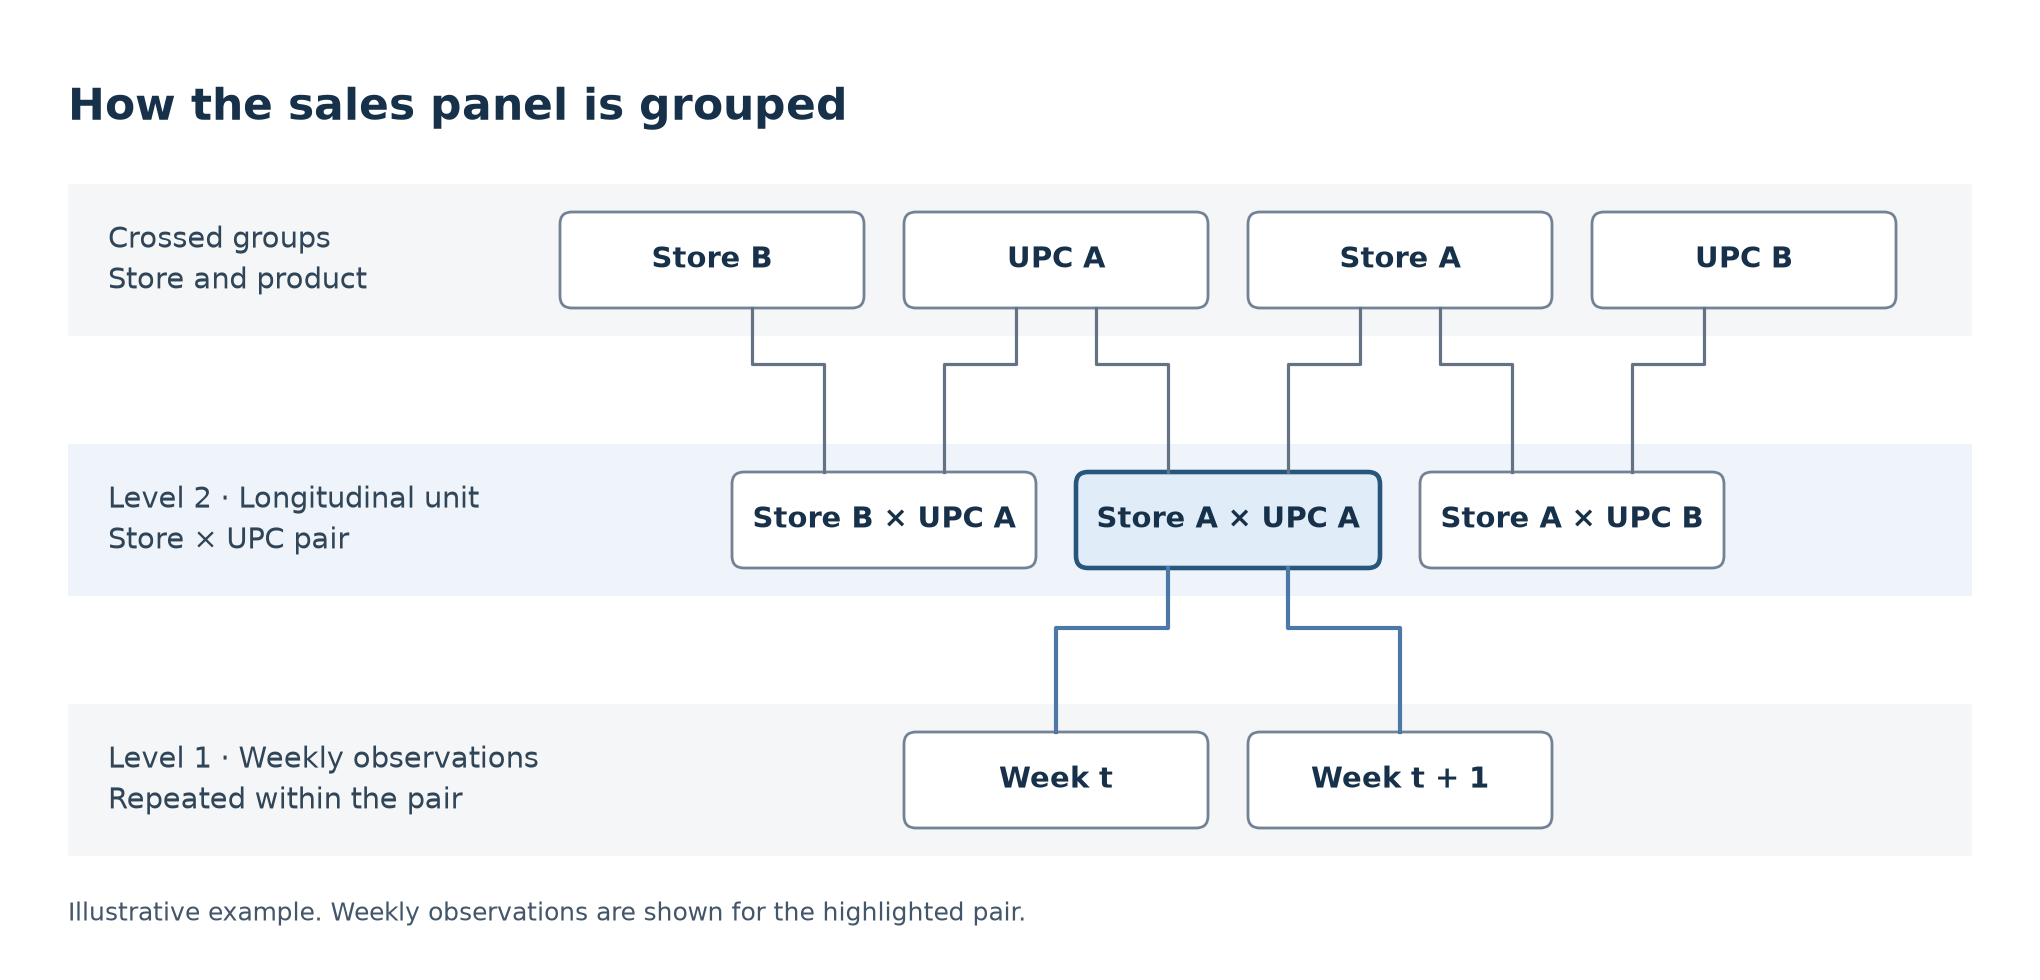

In [5]:
fig = viz.plot_panel_structure(LANG)

The figure uses **three bands** to show crossed groups, pairs, and their weekly observations. C0 estimates random intercepts for store, UPC, and pair (`STORE_NUM:UPC`). Weeks within the same pair share all three intercepts. Different pairs may share only the store or only the UPC. The calendar week is shared by pairs observed on that date and enters C0 through fixed trend and seasonality controls.

This structure motivates multilevel modelling. In notebook 02's null model M4, fitted on training data only, **57.2%** of `LOG_UNITS` variance was attributed to UPC, **9.6%** to store, **8.5%** to the pair, and **24.6%** to the residual. Two weeks within the same pair share all three grouping components, implying a **75.4%** modelled correlation under M4's residual assumption. Notebook 03 separately examines the dependence that remains between weeks after fitting the model.

## 1. Overview and cleaning

The cleaned panel was read from `data/processed/panel.parquet`. The table below summarises its size and the period covered.

In [6]:
eda.panel_overview(panel).to_frame("panel")

,panel
rows,524926
stores,77
upcs,55
pairs,3909
weeks,156
first_week,2009-01-14 00:00:00
last_week,2012-01-04 00:00:00


The cleaning rules (decisions D6 to D10 of the decision log) were applied before this analysis. The counts are panel rows.

| Rule | Treatment | Rows affected |
|---|---|---|
| D6 | Stores with an ambiguous segment (4503 and 17627) flagged and excluded from the segment models | 13,693 (2.6%) |
| D7 | Rows with null or non-positive `PRICE` dropped | 24 |
| D8 | Null `BASE_PRICE` filled using only the history of the pair: 44 rows with the previous week and 141 with the fallback `BASE_PRICE = PRICE`, which sets the discount of the row to zero and always occurs in promotion weeks (flags `BASE_IMPUTED` and `BASE_FALLBACK`) | 185 (44 + 141) |
| D9 | `OUTLIER_UPV` (units per visit > 5) excluded from the modelling sample; `OUTLIER_VPH` only flagged | 67 / 293 |
| D10 | Price above 1.05 × base flagged (`PRICE_ABOVE_BASE`) but kept | 2,071 |

Of the 524,926 rows, 524,859 form the modelling sample (`IN_MODEL`), that is, all except the 67 `OUTLIER_UPV` rows.

## 2. Temporal split (D11, revised)

The first 104 weeks form the training sample, and only they were used to fit models and select specifications. The last 52 weeks (one full seasonal cycle, from 2011-01-12 to 2012-01-04) form the **retrospective temporal evaluation window with prior exploratory exposure**. No model was fitted on them, but this exploratory analysis (the weekly units, the overview and the promotion rates) and the exploratory OLS of `PROJECT_BRIEF.md`, with the price-variation profile, used the whole panel, so the window is not an untouched test set. The formulations motivated by that exploration, the price decomposition of D12 included, are development decisions. No predictive comparison has been computed on this window so far, and the out-of-sample comparison (Tashman, 2000) will follow a protocol recorded before the candidates are fitted (Nosek et al., 2018; Weston et al., 2019). In the tables and charts, the label "test" designates this window.

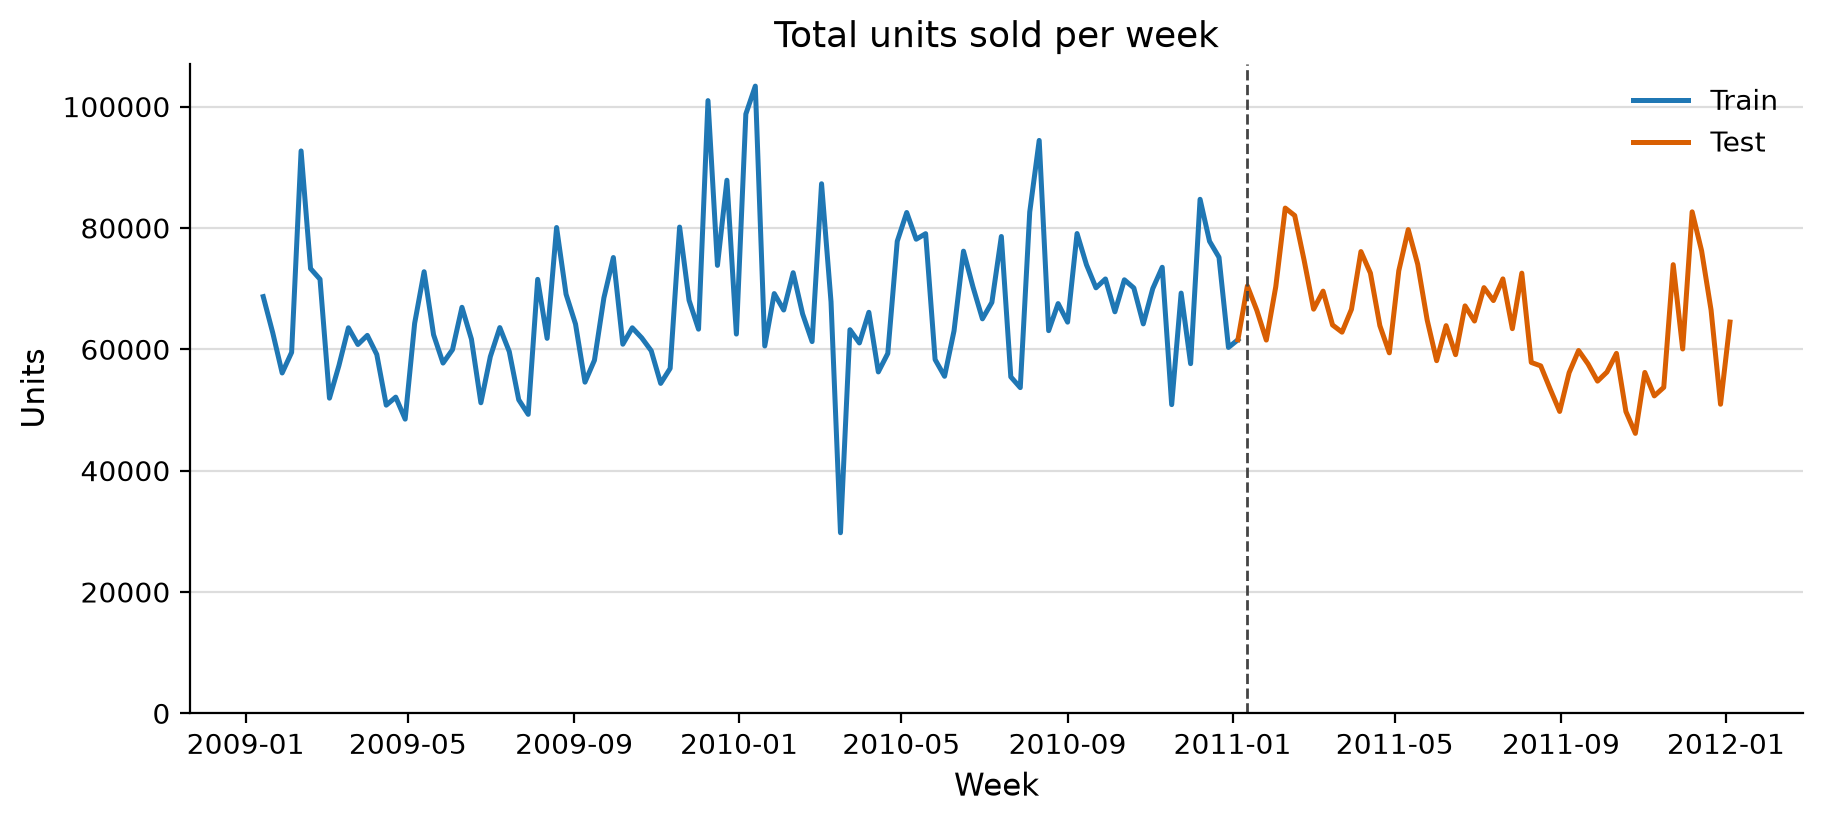

In [7]:
weekly = eda.weekly_units(panel)
fig = viz.plot_weekly_units(weekly, LANG)

In [8]:
split_sizes = pd.DataFrame(
    {"rows": [len(train), len(test)], "pairs": [train["PAIR_ID"].nunique(), test["PAIR_ID"].nunique()]},
    index=[t("legend_train", LANG), t("legend_test", LANG)],
)
display(split_sizes)
display(pd.Series({"pairs_only_in_test": len(set(test["PAIR_ID"]) - set(train["PAIR_ID"]))}).to_frame("n"))

,rows,pairs
Train,347092,3859
Test,177767,3870


,n
pairs_only_in_test,50


The training sample has 347,092 rows in 3,859 pairs, and the test sample has 177,767 rows in 3,870 pairs. Fifty pairs appear only in the evaluation window: they have no training history, so their predictions will rely only on the store and product effects.

## 3. Pair coverage

The histogram counts the training weeks of each store × product pair.

,n_weeks_train
count,"3,859.000"
mean,89.944
std,22.830
min,1.000
25%,86.000
50%,102.000
75%,104.000
max,104.000


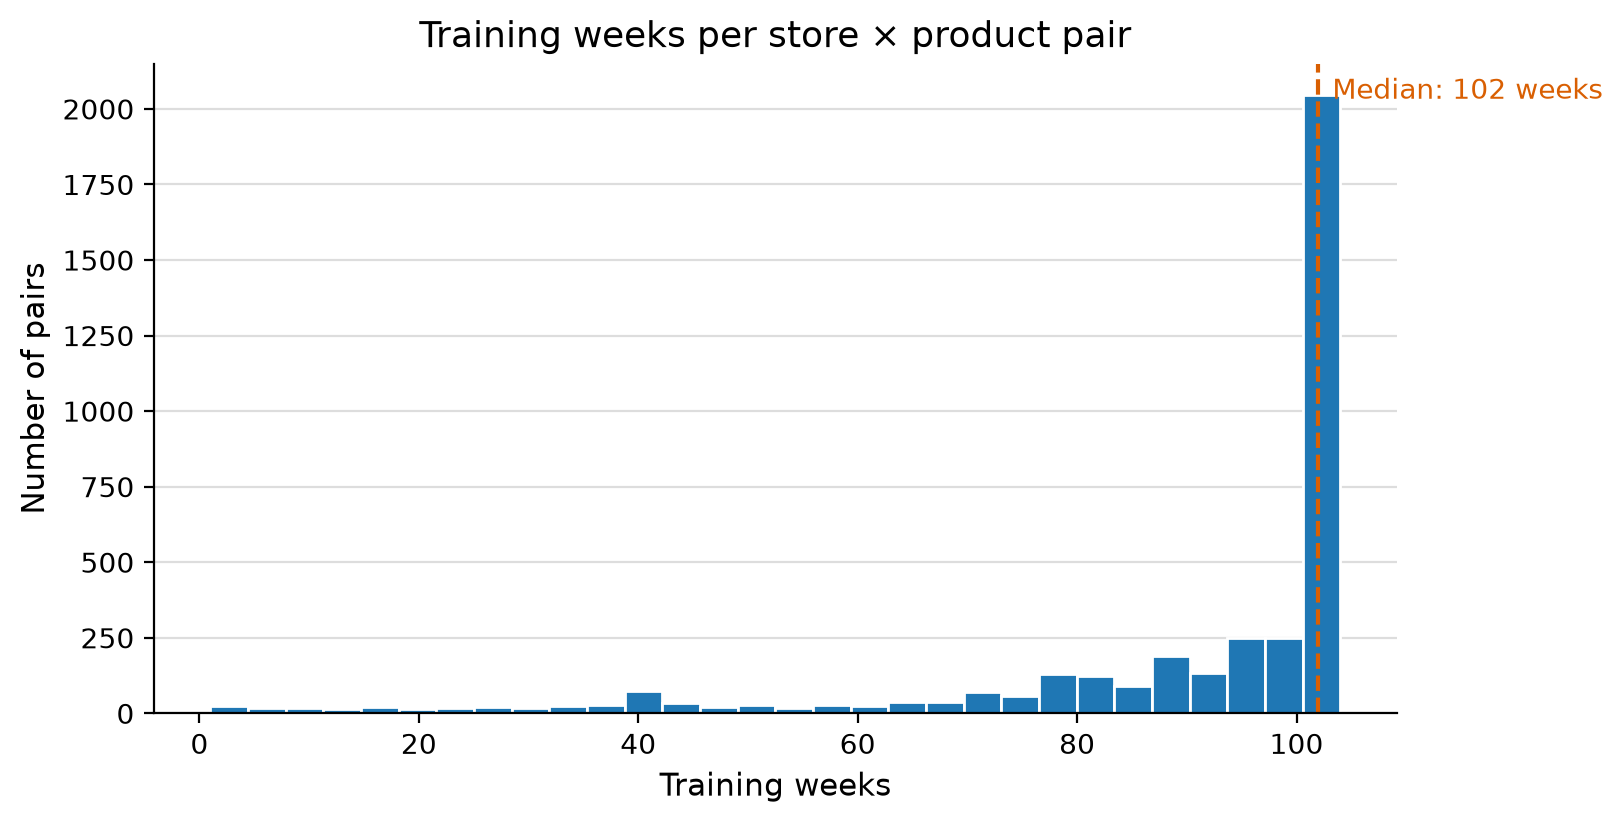

In [9]:
coverage = eda.pair_coverage(train)
fig = viz.plot_pair_coverage(coverage, LANG)
coverage["n_weeks_train"].describe().to_frame()

The median is 102 training weeks per pair, and 1,537 pairs have all 104 weeks. The panel is therefore unbalanced: 25% of the pairs have 86 weeks or fewer, and some pairs have a single week. Such pairs carry little information of their own, which is where partial pooling helps.

## 4. Promotions

The rates below are the share of rows with each promotion on, in the whole panel, overall and by category. `BELOW_BASE` marks a price below 95% of the base price.

,FEATURE,DISPLAY,TPR_ONLY,ANY_PROMO,BELOW_BASE,n
all,0.084,0.110,0.135,0.285,0.247,524926


,FEATURE,DISPLAY,TPR_ONLY,ANY_PROMO,BELOW_BASE,n
CATEGORY,,,,,,
BAG SNACKS,0.025,0.128,0.163,0.304,0.230,127459
COLD CEREAL,0.096,0.088,0.110,0.237,0.221,169687
FROZEN PIZZA,0.167,0.147,0.086,0.307,0.270,111264
ORAL HYGIENE PRODUCTS,0.054,0.087,0.187,0.312,0.284,116516


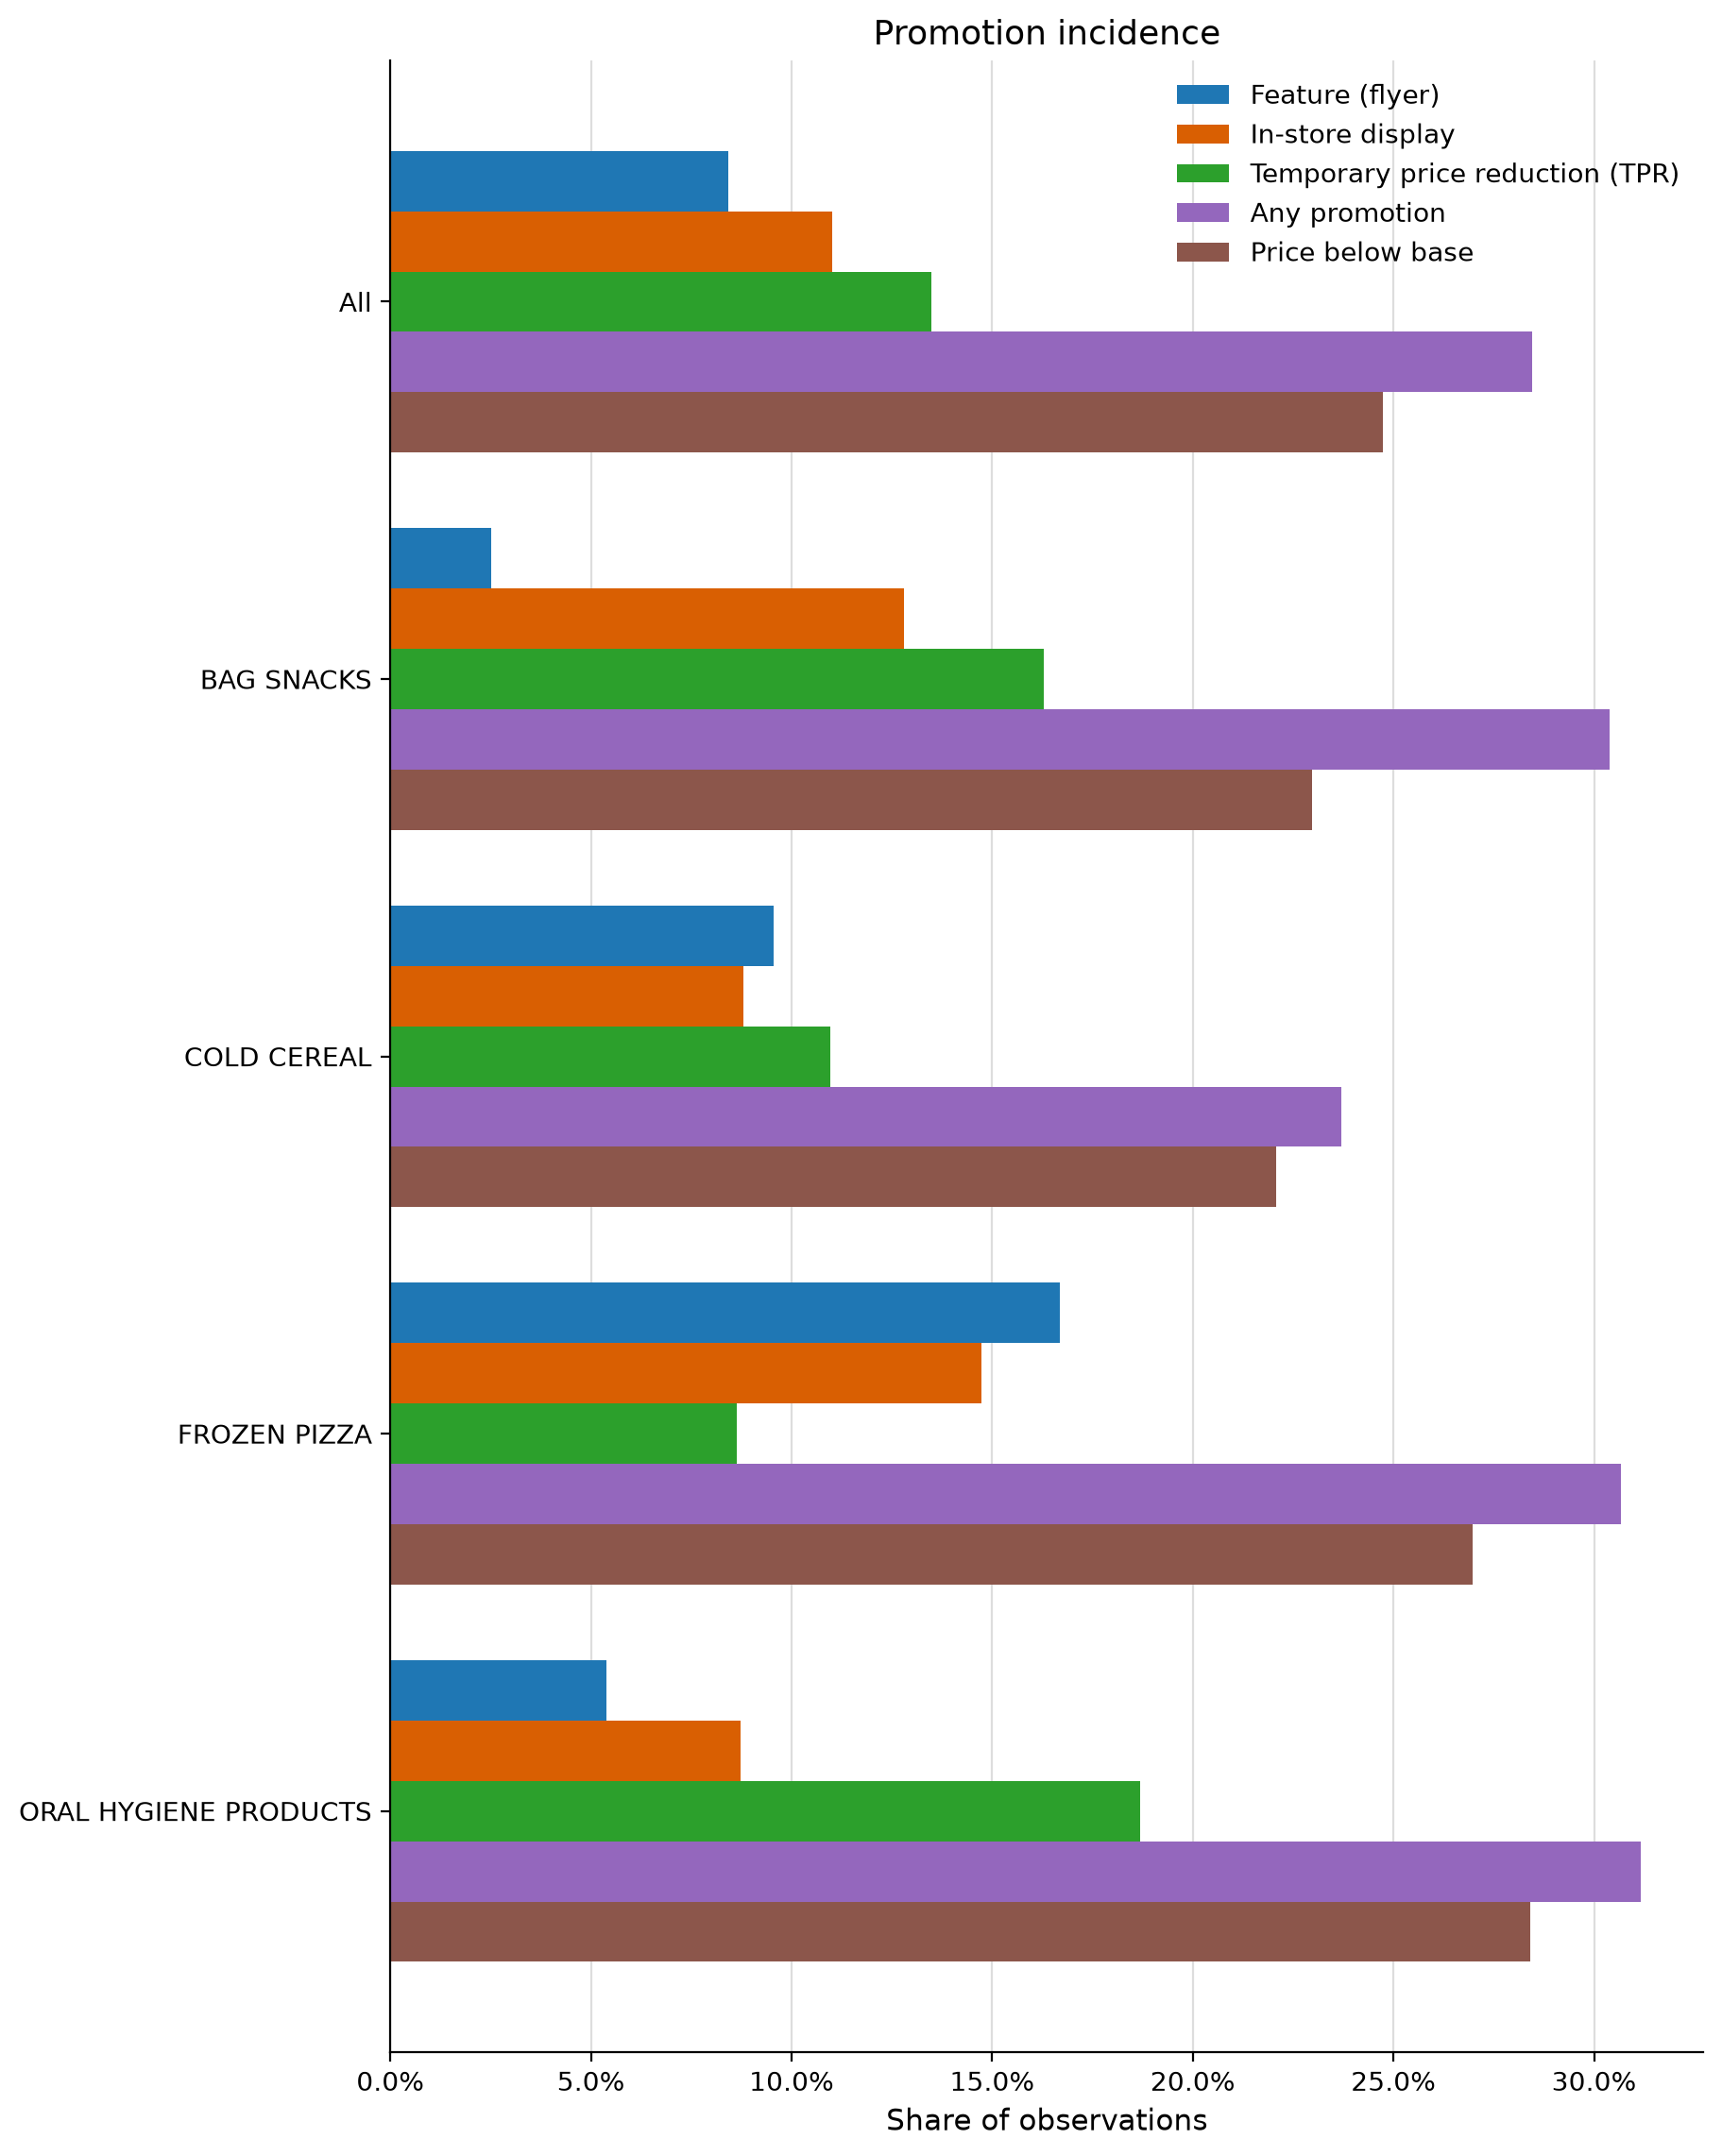

In [10]:
display(eda.promo_rates(panel))
rates_by_category = eda.promo_rates(panel, "CATEGORY")
display(rates_by_category)
fig = viz.plot_promo_rates(pd.concat([eda.promo_rates(panel), rates_by_category]), LANG)

In [11]:
tpr = panel["TPR_ONLY"].astype(bool).rename("TPR_ONLY")
feature_or_display = (panel["FEATURE"].astype(bool) | panel["DISPLAY"].astype(bool)).rename("FEATURE or DISPLAY")
display(pd.crosstab(tpr, feature_or_display))
below_base = (panel["PRICE"] < 0.95 * panel["BASE_PRICE"]).rename(t("promo_below_base", LANG))
any_promo = panel["ANY_PROMO"].astype(bool).rename(t("promo_any_promo", LANG))
display(pd.crosstab(below_base, any_promo))

FEATURE or DISPLAY,False,True
TPR_ONLY,,
False,375541,78652
True,70733,0


Any promotion,False,True
Price below base,,
False,375541,19555
True,0,129830


Some promotion is active in 28.5% of the rows: feature in 8.4%, display in 11.0% and TPR in 13.5%. The first cross-tabulation shows that `TPR_ONLY` never coincides with feature or display (0 rows), by definition of the variable. The second shows that a price below 95% of base never occurs without a promotion (0 rows), although 19,555 rows with a promotion have no price cut of 5% or more; the remaining 129,830 promotion rows have a price below base. The rates differ across categories (for instance, frozen pizza has the highest feature share, 16.7%, and bag snacks the lowest, 2.5%), so the type of promotion depends on the product.

## 5. Price variation

The price variation within each pair (standard deviation of `LOG_PRICE`, in the training sample) is the signal that identifies the elasticity.

In [12]:
variation = eda.price_variation(train)
variation[["sd_log_price", "share_below_base"]].describe()

,sd_log_price,share_below_base
count,"3,856.000","3,859.000"
mean,0.121,0.242
std,0.063,0.141
min,0.000,0.000
25%,0.079,0.132
50%,0.111,0.231
75%,0.156,0.327
max,0.876,0.990


The median standard deviation of log(price) within a pair is 0.111 (about 11%), and pairs spend 24% of their weeks, on average, with a price below base. There is enough variation to estimate the elasticity in most pairs, but it is concentrated in promotion weeks, which makes it harder to separate the effect of price from the effect of the promotion itself.

## 6. Descriptive variance shares

For each grouping, the fraction of the variance of `LOG_UNITS` lying between groups (eta squared) was computed on the training sample. The computation is descriptive and done one grouping at a time; because store, product and pair are not mutually nested, the shares do not sum to 1.

,group,n_groups,between_share
0,STORE_NUM,77,0.067
1,UPC,55,0.533
2,PAIR_ID,3859,0.727


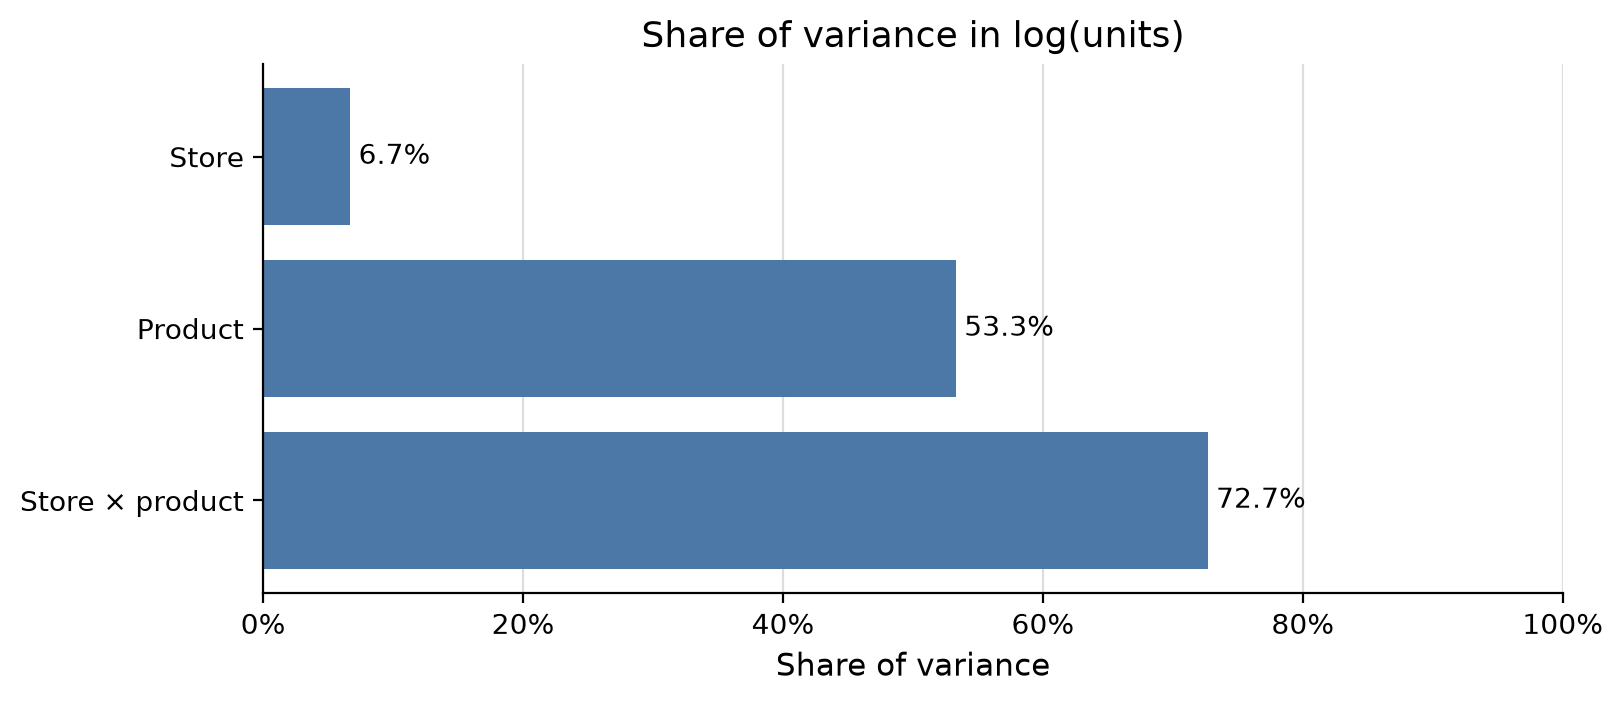

In [13]:
shares = eda.variance_shares(train)
display(shares)
fig = viz.plot_variance_shares(shares, LANG, share_col="between_share")

The product explains 53.3% of the variance of log(units), the store 6.7% and the store × product pair 72.7% (the pair contains both and their interaction). These shares do not come from a model and do not separate effects: the pair has 3,859 means and therefore tends to be larger. They motivate the crossed random-effects null model (Baayen et al., 2008) of notebook 02, which decomposes the variance into store, product, interaction and residual consistently.

## 7. Raw promotion lift

The raw lift compares, within each pair, the log of units in weeks with each promotion on against weeks with no promotion at all (training sample).

,lift_log,lift_pct,n_weeks
promo,,,
FEATURE,1.082,1.951,28964
DISPLAY,0.827,1.287,37756
TPR_ONLY,0.281,0.325,47610


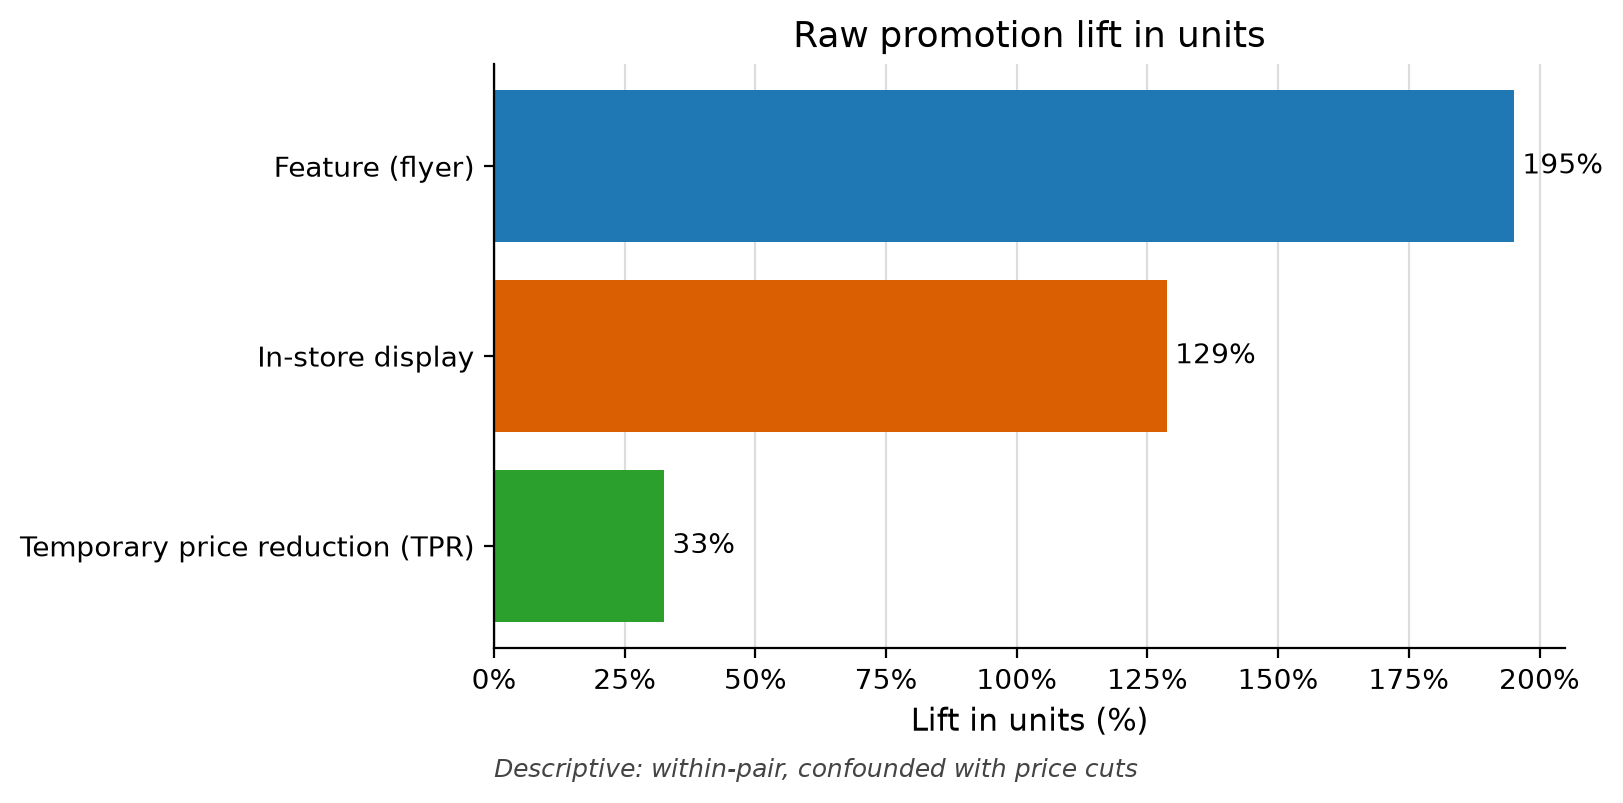

In [14]:
lift = eda.raw_promo_lift(train)
display(lift)
fig = viz.plot_raw_promo_lift(lift, LANG)

The raw lift was 195% for feature, 129% for display and 33% for TPR. These numbers are descriptive and not causal: each promotion is confounded with the price cut and with the other promotions, and feature and display may be applied to the products and weeks with the highest demand. Separating the effect of price from the effect of each promotion is the task of the models.

## 8. Discount slopes estimated pair by pair

The briefing section states that estimating each store × product pair separately can give noisy elasticities. To check that statement, one OLS was fitted for each pair on the training weeks (0 to 103), with the specification `LOG_UNITS ~ LOG_DISC + FEATURE + DISPLAY + TPR_ONLY`, where `LOG_DISC = log(price / base price)`. Pairs with at least 8 weeks enter, and a term without variation in the pair, or collinear with the previous ones, is not estimated (the pair is left without a slope when it is `LOG_DISC` that does not vary). The fit is done by a script (`scripts/fit_pair_ols_slopes.py`), which stores the run read below, and the notebook only reads the results. Because `LOG_DISC` is negative in discount weeks, a negative slope means that more discount comes with more units; a positive slope means the opposite.

20261126-104604-bd48a521


,History stratum,Pairs,Pairs with slope > 0,Share with slope > 0 (%),5th percentile,25th percentile,Median,75th percentile,95th percentile
0,All,3788,751,19.83,-5.40,-2.85,-1.65,-0.33,3.18
1,< 26 weeks,69,25,36.23,-10.54,-1.74,0.00,0.54,3.45
2,26-77 weeks,543,148,27.26,-6.89,-3.34,-1.52,0.21,5.61
3,≥ 78 weeks,3176,578,18.20,-4.86,-2.82,-1.68,-0.46,2.69


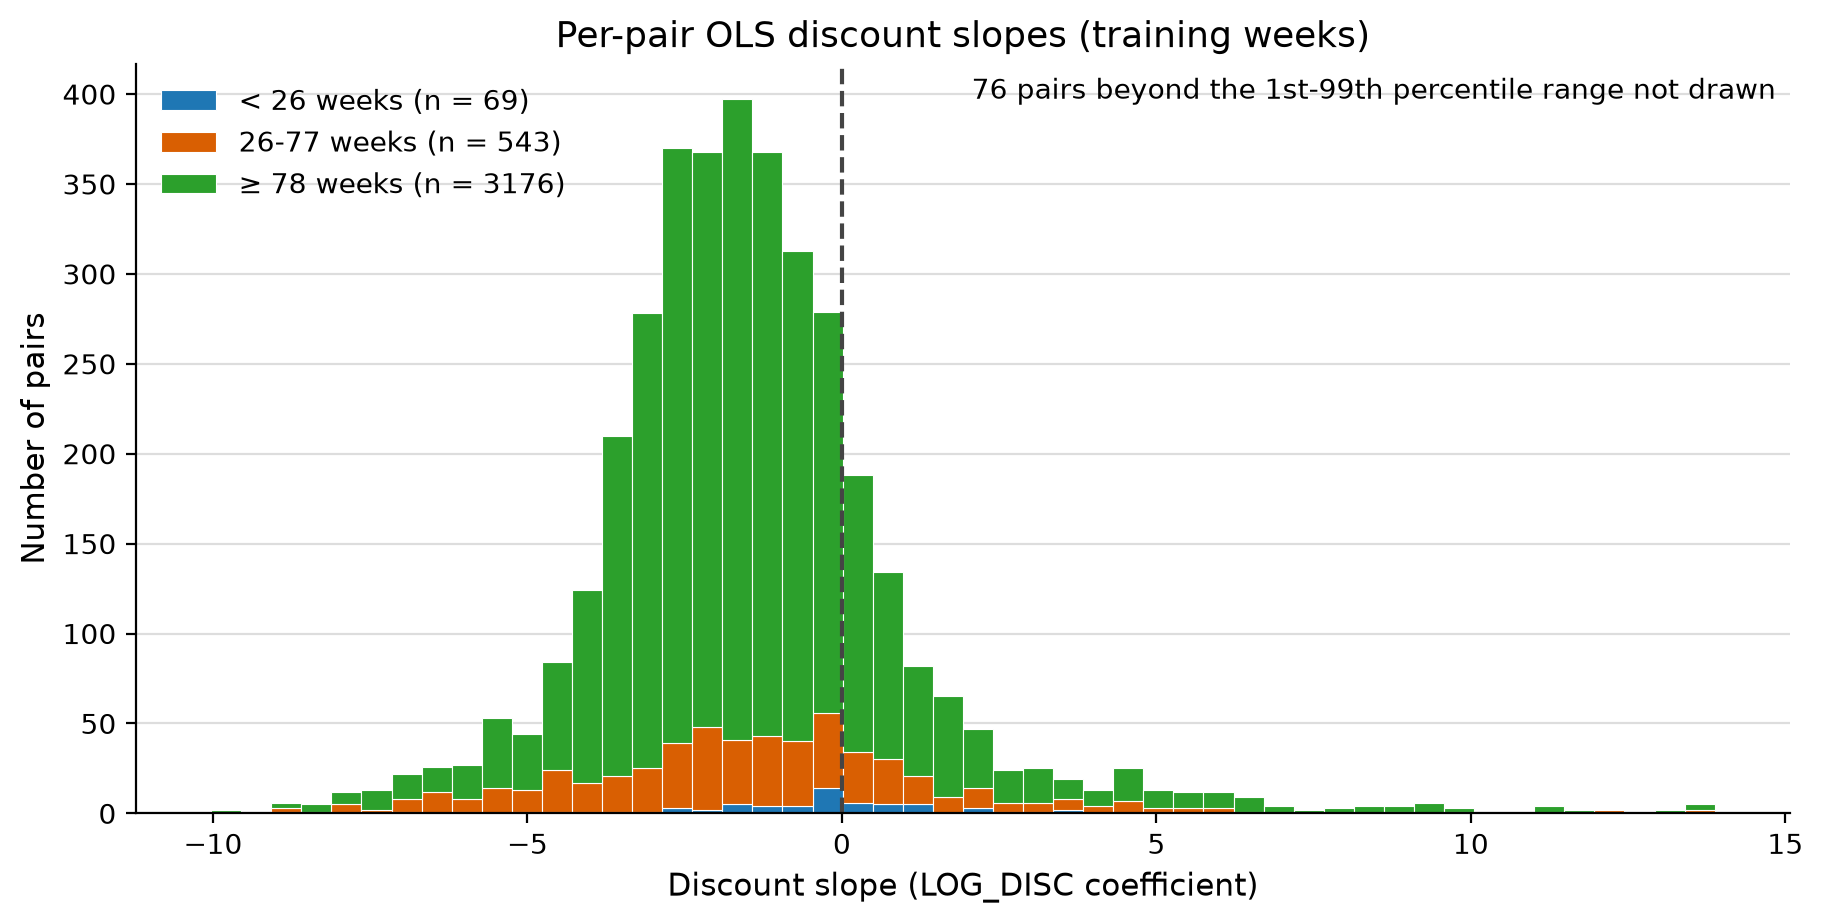

In [15]:
from retail_multilevel.i18n import localize_columns, stratum_label
from retail_multilevel.runs import load_run

pair_run = load_run("pair_ols_slopes", "20261126-104604-bd48a521")
print(pair_run.run_id)
pair_slopes = pair_run.load_table("slopes")
pair_summary = pair_run.load_table("summary")
pair_summary["stratum"] = [stratum_label(x, LANG) for x in pair_summary["stratum"]]
with pd.option_context("display.float_format", "{:,.2f}".format):
    display(localize_columns(pair_summary, LANG))
fig = viz.plot_pair_slopes(pair_slopes, LANG)

Of the 3,859 training pairs, 3,788 had the discount slope estimated: 42 pairs have fewer than 8 weeks and 29 were fitted without estimable discount variation. The median slope is −1.65, but the dispersion is large, with the 5th percentile at −5.40 and the 95th percentile at +3.18. A total of 751 pairs (19.8%) have a positive slope. The share is 36.2% among pairs with fewer than 26 weeks (25 of 69), 27.3% among those with 26 to 77 weeks (148 of 543) and 18.2% among those with 78 weeks or more (578 of 3,176). It decreases with history, but it still reaches almost one pair in five among the longest ones. Slopes that are exactly zero, which occur in pairs with constant units, and coefficients that are zero up to rounding are not counted as positive.

A positive discount slope has no economic sense: it says that a price cut comes with fewer units. In a single pair, this signals noise, because of the small number of discount weeks, or confounding with other factors, such as the timing of promotions. This behaviour motivates the partial pooling (Gelman & Hill, 2007) tested in notebooks 02 to 04, in which each pair borrows information from the others instead of being estimated alone.

## 9. Summary

The panel has 524,926 rows, 77 stores, 55 products, 3,909 pairs and 156 weeks, and the modelling sample excludes 67 rows. The last 52 weeks form the retrospective evaluation window, with prior exploratory exposure, and 50 pairs appear only in that period. The training panel is unbalanced (median of 102 weeks per pair), which favours partial pooling. Estimated pair by pair, 19.8% of the discount slopes are positive, which reinforces this motivation.

Some promotion is active in 28.5% of the rows; `TPR_ONLY` never coincides with feature or display, and a price below base occurs only under promotion. The raw promotion lift is large but is confounded with price. As for the variance of log(units), it lies mostly between products and pairs, and the descriptive shares are not additive.

Notebook 02 reads the null models fitted by script (`runs.load_run("null_models", "20261124-114105-b15be79c")`) and decomposes the variance into store, product, interaction and residual.

## References

Baayen, R. H., Davidson, D. J., & Bates, D. M. (2008). Mixed-effects modeling with crossed random effects for subjects and items. *Journal of Memory and Language, 59*(4), 390–412. https://doi.org/10.1016/j.jml.2007.12.005

Bijmolt, T. H. A., van Heerde, H. J., & Pieters, R. G. M. (2005). New empirical generalizations on the determinants of price elasticity. *Journal of Marketing Research, 42*(2), 141–156. https://doi.org/10.1509/jmkr.42.2.141.62296

Blattberg, R. C., & Neslin, S. A. (1989). Sales promotion: The long and the short of it. *Marketing Letters, 1*(1), 81–97. https://doi.org/10.1007/BF00436151

Gelman, A., & Hill, J. (2007). *Data analysis using regression and multilevel/hierarchical models*. Cambridge University Press. https://doi.org/10.1017/CBO9780511790942

Hyndman, R. J., & Athanasopoulos, G. (2021). *Forecasting: Principles and practice* (3rd ed.). OTexts. https://otexts.com/fpp3/

Nosek, B. A., Ebersole, C. R., DeHaven, A. C., & Mellor, D. T. (2018). The preregistration revolution. *Proceedings of the National Academy of Sciences, 115*(11), 2600–2606. https://doi.org/10.1073/pnas.1708274114

Raudenbush, S. W., & Bryk, A. S. (2002). *Hierarchical linear models: Applications and data analysis methods* (2nd ed.). Sage. (partial verification: edition year not checked against a primary source)

Sigrist, F. (2022). Gaussian process boosting. *Journal of Machine Learning Research, 23*, 1–46.

Tashman, L. J. (2000). Out-of-sample tests of forecasting accuracy: An analysis and review. *International Journal of Forecasting, 16*(4), 437–450. https://doi.org/10.1016/S0169-2070(00)00065-0

Tellis, G. J. (1988). The price elasticity of selective demand: A meta-analysis of econometric models of sales. *Journal of Marketing Research, 25*(4), 331–341. https://doi.org/10.1177/002224378802500401

Weston, S. J., Ritchie, S. J., Rohrer, J. M., & Przybylski, A. K. (2019). Recommendations for increasing the transparency of analysis of preexisting data sets. *Advances in Methods and Practices in Psychological Science, 2*(3), 214–227. https://doi.org/10.1177/2515245919848684